# Modelo eólico paso a paso: de los datos crudos al modelo exportado

Este notebook reproduce, de forma didáctica y honesta, el flujo del paper
*Cross-Site Prospective Estimation of HAWT Energy Output* con los datos de la carpeta `data/`:

1. Cargar y entender los datos crudos
2. Limpiarlos y construir las variables (features)
3. **Exportar el dataset limpio**
4. Validar bien: partición cronológica y CV en bloques (frente a la aleatoria, que es optimista)
5. Línea base física coherente (en voltios, con la carga de 100 Ω)
6. Entrenar el modelo final (Extra Trees)
7. **Exportar el modelo** (`joblib` + metadatos) y volver a cargarlo
8. Aplicarlo a João Pessoa, con diagnóstico fuera de distribución e incertidumbre
9. Convertir tensión a energía (`E = V²/R · Δt`)

> Los resultados que salgan aquí **no son los del paper**: `data_cajica_2022_crudo.csv` cubre junio–agosto de 2022
> (no junio 2022–febrero 2023) y tiene filas duplicadas. Sirve para aprender el flujo y para detectar inconsistencias.

## 0. Preparación

In [1]:
from pathlib import Path
import json, math, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BASE = Path.cwd()
DATA, MODELS, OUT = BASE / "data", BASE / "models", BASE / "outputs"
for d in (MODELS, OUT):
    d.mkdir(exist_ok=True)

SEED = 42
R_LOAD = 100.0          # ohm, carga resistiva del experimento
ALT_CAJICA, ALT_JPA = 2558.0, 40.0   # m s.n.m.
print("pandas", pd.__version__, "| sklearn", sklearn.__version__, "| python", platform.python_version())

pandas 3.0.6 | sklearn 1.9.1 | python 3.11.15


## 1. Cargar los datos crudos de Cajicá

El archivo no trae cabecera; los nombres salen del script original (`referencia/v_g1_original.py`).

In [2]:
COLS = ['ID','velU','velV','velW','xang','xejz','xmag','V_G1','FR_G1','P_AT','EG1',
        'V_G2','FR_G2','P_AT2','EG2','HUMEDAD_SUELO','HUMEDAD_RELATIVA','TEMPERATURA','fecha']
raw = pd.read_csv(DATA / "data_cajica_2022_crudo.csv", names=COLS, header=None, parse_dates=['fecha'])
print(raw.shape)
raw[['xang','xmag','V_G1','HUMEDAD_RELATIVA','TEMPERATURA','fecha']].head()

(150060, 19)


,xang,xmag,V_G1,HUMEDAD_RELATIVA,TEMPERATURA,fecha
0,10.0,0.0,0.0,54.0,21.4,2022-06-17 22:37:00
1,10.0,0.0,0.0,54.0,21.4,2022-06-17 22:38:00
2,10.0,0.0,0.0,54.0,21.4,2022-06-17 22:40:00
3,10.0,0.0,0.0,54.0,21.4,2022-06-17 22:41:00
4,10.0,0.0,0.0,54.0,21.4,2022-06-17 22:42:00


In [3]:
print("Rango de fechas :", raw.fecha.min(), "->", raw.fecha.max())
print("Fechas únicas   :", raw.fecha.nunique(), "de", len(raw), "filas")
print("Ordenado        :", raw.fecha.is_monotonic_increasing)
print("V_G1 == 0       : %.1f %%" % (100 * (raw.V_G1 == 0).mean()))
print("V_G1 máximo     :", raw.V_G1.max(), " <- valor imposible: hay que filtrar")
raw[['xang','xmag','V_G1','HUMEDAD_RELATIVA','TEMPERATURA']].describe().T

Rango de fechas : 2022-06-17 22:37:00 -> 2022-08-19 19:49:00
Fechas únicas   : 59758 de 150060 filas
Ordenado        : False
V_G1 == 0       : 93.5 %
V_G1 máximo     : 38400.0  <- valor imposible: hay que filtrar


,count,mean,std,min,25%,50%,75%,max
xang,150060.0,118.291404,99.519756,0.0,39.00,84.000,180.50,359.0
xmag,150060.0,2.494002,45.268762,0.0,1.03,1.545,2.28,4095.0
V_G1,150060.0,2.009114,243.003206,0.0,0.00,0.000,0.00,38400.0
HUMEDAD_RELATIVA,150060.0,46.976234,6.232385,28.0,43.00,46.000,51.00,99.0
TEMPERATURA,150060.0,18.497946,5.000437,8.5,14.40,17.000,22.60,34.7


## 2. Limpieza y construcción de variables

Reglas (las mismas del script original, más una corrección):

- Quitar duplicados por `fecha` y **ordenar cronológicamente** (imprescindible para validar en el tiempo).
- Valores imposibles → 0 (`xmag > 65`, `V_G1 > 25`), como en el original.
- `velU = mag·cos(θ)` y `velV = mag·sin(θ)`: **θ está en grados**, hay que pasarlo a radianes.
  El script original llama `math.cos(xang)` directamente (radianes), lo que mezcla la convención con João Pessoa.
- Densidad del aire con la Ec. (3): `ρ = 1.225·(288/(T+273))·exp(-h/8435)`.

In [4]:
def air_density(temp_c, h):
    return 1.225 * (288.0 / (temp_c + 273.0)) * np.exp(-h / 8435.0)

def build_features(df, altitude):
    # df debe tener: xang (grados), xmag (m/s), HUMEDAD_RELATIVA, TEMPERATURA, fecha
    out = pd.DataFrame(index=df.index)
    th = np.deg2rad(df['xang'])
    out['xang'] = df['xang']
    out['velU'] = df['xmag'] * np.cos(th)
    out['velV'] = df['xmag'] * np.sin(th)
    out['air_dens'] = air_density(df['TEMPERATURA'], altitude)
    out['rel_hum'] = df['HUMEDAD_RELATIVA']
    out['hour'] = df['fecha'].dt.hour
    out['xmag'] = df['xmag']
    out['temp'] = df['TEMPERATURA']
    return out

FEATURES = ['xang','velU','velV','air_dens','rel_hum','hour','xmag','temp']

clean = (raw.drop_duplicates('fecha', keep='last')
            .sort_values('fecha')
            .reset_index(drop=True))
clean.loc[clean.xmag > 65, 'xmag'] = 0
clean.loc[clean.V_G1 > 25, 'V_G1'] = 0
clean = clean.dropna(subset=['xang','xmag','V_G1','HUMEDAD_RELATIVA','TEMPERATURA'])

X = build_features(clean, ALT_CAJICA)
y = clean['V_G1'].rename('V_G1')
dataset = pd.concat([clean[['fecha']], X, y], axis=1)
print(len(raw), "->", len(dataset), "filas tras limpiar")
dataset.describe().T[['count','mean','std','min','max']]

150060 -> 59758 filas tras limpiar


,count,mean,std,min,max
fecha,59758,2022-07-19 23:09:55.546035,NaN,2022-06-17 22:37:00,2022-08-19 19:49:00
xang,59758.0,117.542034,103.32494,0.0,359.0
velU,59758.0,0.393003,1.487226,-10.049644,7.769939
velV,59758.0,0.707297,1.174655,-5.309191,8.995638
air_dens,59758.0,0.894168,0.015058,0.846636,0.925435
rel_hum,59758.0,47.09903,6.246242,28.0,99.0
hour,59758.0,11.517303,6.996586,0.0,23.0
xmag,59758.0,1.765948,1.061961,0.0,10.105
temp,59758.0,18.426775,4.958773,8.5,34.7
V_G1,59758.0,0.358542,1.630556,0.0,21.0


### Comprobación de equivalencia entre sitios

Misma función, mismas unidades: así João Pessoa y Cajicá quedan definidos igual
(ver Tabla de equivalencia del paper). Un ejemplo con la primera fila de la Tabla IV (θ = 86°, mag = 3.1 m/s):

In [5]:
ej = pd.DataFrame({'xang':[86.0],'xmag':[3.1],'HUMEDAD_RELATIVA':[56.0],'TEMPERATURA':[31.0],
                   'fecha':pd.to_datetime(['2025-04-17 16:00'])})
build_features(ej, ALT_JPA).round(4)   # velU debe dar 0.216 y velV 3.092, como en la Tabla IV

,xang,velU,velV,air_dens,rel_hum,hour,xmag,temp
0,86.0,0.2162,3.0924,1.155,56.0,16,3.1,31.0


## 3. Exportar el dataset limpio

Guarda siempre el dataset ya procesado: es lo que permite reproducir los resultados sin repetir la limpieza.

In [6]:
dataset.to_csv(DATA / "dataset_cajica_limpio.csv", index=False)
# Parquet conserva tipos y es más rápido (necesita pyarrow; si no está, se omite)
try:
    dataset.to_parquet(DATA / "dataset_cajica_limpio.parquet", index=False)
except Exception as e:
    print("parquet omitido:", type(e).__name__)
print(sorted(p.name for p in DATA.iterdir()))

parquet omitido: ImportError
['data_cajica_2022_crudo.csv', 'dataset_cajica_limpio.csv', 'estacion_jpa_2025_crudo.csv']


## 4. Validación honesta

Las observaciones meteorológicas consecutivas están muy correlacionadas. Si se mezclan al azar,
el modelo "ve" minutos vecinos de los de prueba y el resultado sale **optimista**.
Comparamos tres esquemas con el mismo modelo:

| Esquema | Qué mide |
|---|---|
| KFold aleatorio (10) | interpolación dentro del mismo periodo (optimista) |
| TimeSeriesSplit (5, ventana creciente) | predicción hacia el futuro |
| Último 20 % cronológico | prueba independiente final |

Todo el preprocesado (escalado) va **dentro de un `Pipeline`**, así se ajusta solo con los datos de entrenamiento de cada partición.

In [7]:
def rmsle(y, p):
    return float(np.sqrt(np.mean((np.log1p(np.clip(p, 0, None)) - np.log1p(np.clip(y, 0, None))) ** 2)))

def metrics(y, p):
    mse = mean_squared_error(y, p)
    return {'MAE': mean_absolute_error(y, p), 'MSE': mse, 'RMSE': math.sqrt(mse),
            'R2': r2_score(y, p), 'RMSLE': rmsle(y, p)}

def make_model():
    return Pipeline([('scale', StandardScaler()),
                     ('et', ExtraTreesRegressor(n_estimators=200, min_samples_leaf=1,
                                                n_jobs=-1, random_state=SEED))])

def cv_report(splitter, X, y):
    rows = []
    for tr, te in splitter.split(X):
        m = make_model().fit(X.iloc[tr], y.iloc[tr])
        rows.append(metrics(y.iloc[te], m.predict(X.iloc[te])))
    return pd.DataFrame(rows)

Xd, yd = dataset[FEATURES], dataset['V_G1']
res = {
 'KFold aleatorio (10)': cv_report(KFold(10, shuffle=True, random_state=SEED), Xd, yd),
 'TimeSeriesSplit (5)':  cv_report(TimeSeriesSplit(5), Xd, yd),
}
summary = pd.DataFrame({k: v.mean() for k, v in res.items()}).T
summary_std = pd.DataFrame({k: v.std() for k, v in res.items()}).T
print("Media por esquema"); display(summary.round(4))
print("Desviación entre folds"); display(summary_std.round(4))

Media por esquema


,MAE,MSE,RMSE,R2,RMSLE
KFold aleatorio (10),0.3406,1.2389,1.1126,0.5329,0.3461
TimeSeriesSplit (5),0.3834,1.5243,1.2246,0.4638,0.3699


Desviación entre folds


,MAE,MSE,RMSE,R2,RMSLE
KFold aleatorio (10),0.0102,0.0767,0.0347,0.0224,0.0069
TimeSeriesSplit (5),0.0959,0.4168,0.1754,0.0563,0.0469


In [8]:
cut = int(len(dataset) * 0.8)
Xtr, Xte, ytr, yte = Xd.iloc[:cut], Xd.iloc[cut:], yd.iloc[:cut], yd.iloc[cut:]
print("Entrenamiento:", dataset.fecha.iloc[0], "->", dataset.fecha.iloc[cut-1])
print("Prueba       :", dataset.fecha.iloc[cut], "->", dataset.fecha.iloc[-1])
final = make_model().fit(Xtr, ytr)
pred_te = final.predict(Xte)
m_et = metrics(yte, pred_te)
pd.Series(m_et).round(4)

Entrenamiento: 2022-06-17 22:37:00 -> 2022-08-08 10:55:00
Prueba       : 2022-08-08 10:56:00 -> 2022-08-19 19:49:00


MAE      0.5370
MSE      2.3607
RMSE     1.5365
R2       0.4971
RMSLE    0.4230
dtype: float64

## 5. Línea base física coherente

La curva teórica da **potencia (W)**, pero el modelo predice **tensión RMS (V)**. Para compararlos hay que convertir:

`P_theory = ½ ρ A Cp v³` (con cut-in 2.5 m/s y cut-out 15 m/s) → `V_RMS = √(η · P_theory · R)`

La eficiencia global `η` (generador + rectificador + cableado) no estaba documentada; aquí se **ajusta por mínimos cuadrados
solo con el entrenamiento** y se declara como supuesto.

In [9]:
A, CP, CUT_IN, CUT_OUT = 0.636, 0.35, 2.5, 15.0

def p_theory(rho, v):
    p = 0.5 * rho * A * CP * v ** 3
    return np.where((v < CUT_IN) | (v > CUT_OUT), 0.0, p)

ptr = p_theory(Xtr['air_dens'].values, Xtr['xmag'].values)
eta = float(np.sum(ytr.values ** 2 * ptr * R_LOAD) / np.sum((ptr * R_LOAD) ** 2))
print("eta ajustada (entrenamiento) = %.4f" % eta)

def v_baseline(rho, v, eta=eta):
    return np.sqrt(np.clip(eta * p_theory(rho, v) * R_LOAD, 0, None))

pred_base = v_baseline(Xte['air_dens'].values, Xte['xmag'].values)
comp = pd.DataFrame({'Extra Trees': m_et,
                     'Curva de potencia (en V)': metrics(yte, pred_base),
                     'Media constante': metrics(yte, np.full(len(yte), ytr.mean()))}).T
comp.round(4)

eta ajustada (entrenamiento) = 0.0330


,MAE,MSE,RMSE,R2,RMSLE
Extra Trees,0.5370,2.3607,1.5365,0.4971,0.4230
Curva de potencia (en V),0.7879,3.0973,1.7599,0.3401,0.6132
Media constante,0.8497,4.7967,2.1901,-0.0219,0.5802


## 6. Importancia de variables y gráfica de resultados

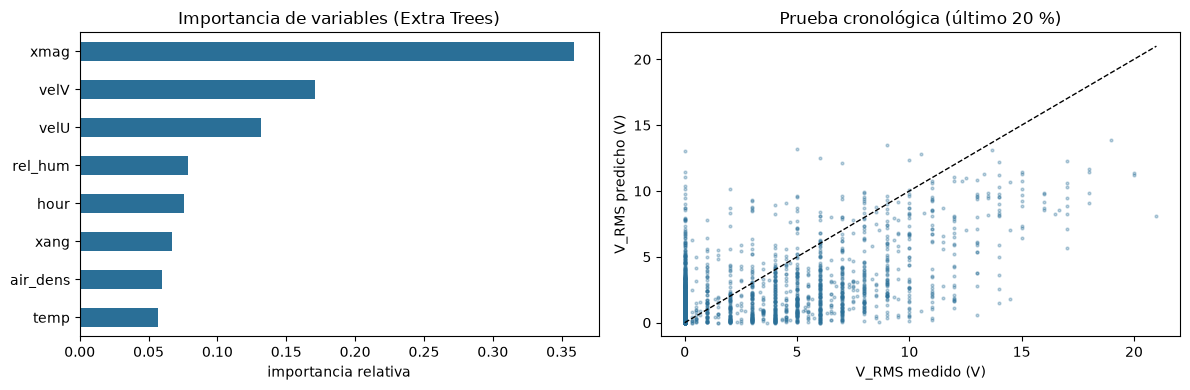

In [10]:
imp = pd.Series(final.named_steps['et'].feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
imp.plot.barh(ax=ax[0], color='#2a6f97'); ax[0].set_title('Importancia de variables (Extra Trees)')
ax[0].set_xlabel('importancia relativa')
ax[1].scatter(yte, pred_te, s=4, alpha=.3, color='#2a6f97')
lim = max(yte.max(), pred_te.max()); ax[1].plot([0, lim], [0, lim], 'k--', lw=1)
ax[1].set_xlabel('V_RMS medido (V)'); ax[1].set_ylabel('V_RMS predicho (V)')
ax[1].set_title('Prueba cronológica (último 20 %)')
plt.tight_layout(); plt.savefig(OUT / 'fig_validacion.png', dpi=200); plt.show()

## 7. Exportar el modelo y volver a cargarlo

Se guardan **dos cosas**: el modelo (pipeline completo, escalado incluido) y sus metadatos
(variables, versiones, métricas, rango de entrenamiento). Sin metadatos no se puede saber después
con qué datos y versiones se entrenó.

In [11]:
final_all = make_model().fit(Xd, yd)       # modelo final: todos los datos limpios
joblib.dump(final_all, MODELS / "extra_trees_vrms.joblib", compress=3)

meta = {
    "target": "V_G1 (V_RMS)",
    "features": FEATURES,
    "angle_convention": "grados; velU=mag*cos(theta), velV=mag*sin(theta), theta desde el eje este",
    "air_density_altitude_train_m": ALT_CAJICA,
    "train_period": [str(dataset.fecha.min()), str(dataset.fecha.max())],
    "n_train": int(len(dataset)),
    "validation_chronological_last20": {k: round(v, 4) for k, v in m_et.items()},
    "baseline_eta": round(eta, 4),
    "feature_ranges_p1_p99": {c: [float(Xd[c].quantile(.01)), float(Xd[c].quantile(.99))] for c in FEATURES},
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
    "seed": SEED,
}
(MODELS / "extra_trees_vrms_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
size_mb = (MODELS / "extra_trees_vrms.joblib").stat().st_size / 1e6
print("modelo guardado: %.1f MB" % size_mb)

modelo guardado: 37.5 MB


In [12]:
# Recargar y comprobar que da exactamente lo mismo (prueba mínima de reproducibilidad)
loaded = joblib.load(MODELS / "extra_trees_vrms.joblib")
meta_loaded = json.loads((MODELS / "extra_trees_vrms_meta.json").read_text())
assert np.allclose(loaded.predict(Xd.iloc[:500][meta_loaded['features']]), final_all.predict(Xd.iloc[:500]))
print("OK: el modelo recargado predice igual")

OK: el modelo recargado predice igual


## 8. Aplicar el modelo a João Pessoa

`estacion_jpa_2025_crudo.csv` es un volcado de la estación con dos formatos mezclados en el mismo archivo
(la columna 0 unas veces es un ID y otras una fecha). Se usa la columna 33 (fecha), y se toman:

| Columna | Variable |
|---|---|
| 2 | temperatura (°C) |
| 4 | humedad relativa (%) |
| 17 | ángulo del viento (°) |
| 19 | velocidad del viento |

> **Supuesto a verificar:** la columna 19 tiene media ≈ 6.0 y las columnas 20 y 21 ≈ 3.76 y 1.68,
> proporciones que corresponden a **km/h, mph y m/s**. Por eso aquí la velocidad en m/s es `col19 / 3.6`.
> Confirma las unidades con quien exportó la estación: **el paper dice 3.41 m/s de media y aquí sale otra cifra**.

In [13]:
jraw = pd.read_csv(DATA / "estacion_jpa_2025_crudo.csv", sep="\t", header=None, na_values=["NULL"], low_memory=False)
jp = pd.DataFrame({
    'fecha': pd.to_datetime(jraw[33], errors='coerce'),
    'TEMPERATURA': pd.to_numeric(jraw[2], errors='coerce'),
    'HUMEDAD_RELATIVA': pd.to_numeric(jraw[4], errors='coerce'),
    'xang': pd.to_numeric(jraw[17], errors='coerce'),
    'xmag': pd.to_numeric(jraw[19], errors='coerce') / 3.6,   # km/h -> m/s (SUPUESTO)
}).dropna().drop_duplicates('fecha').sort_values('fecha').reset_index(drop=True)
print(len(jraw), "->", len(jp), "filas;", jp.fecha.min(), "->", jp.fecha.max())
print("Viento medio JPA = %.2f m/s | Cajicá (entrenamiento) = %.2f m/s" % (jp.xmag.mean(), dataset.xmag.mean()))
dt_med = jp.fecha.diff().median(); print("Intervalo mediano entre registros:", dt_med)
Xjp = build_features(jp, ALT_JPA)[meta_loaded['features']]
Xjp.describe().T[['count','mean','min','max']].round(3)

9415 -> 9229 filas; 2025-03-27 17:05:00 -> 2025-09-05 13:51:00
Viento medio JPA = 1.66 m/s | Cajicá (entrenamiento) = 1.77 m/s
Intervalo mediano entre registros: 0 days 00:10:00


,count,mean,min,max
xang,9229.0,161.942,0.000,359.000
velU,9229.0,-0.870,-7.445,5.499
velV,9229.0,0.657,-4.422,6.962
air_dens,9229.0,1.171,1.153,1.198
rel_hum,9229.0,77.754,43.000,97.000
hour,9229.0,11.468,0.000,23.000
xmag,9229.0,1.664,0.000,7.611
temp,9229.0,26.781,20.100,31.500


### Diagnóstico fuera de distribución

Un árbol no extrapola: solo devuelve valores vistos en el entrenamiento. Antes de creer las predicciones hay que medir
**qué fracción de los datos nuevos cae fuera del rango de entrenamiento** (percentiles 1–99).

In [14]:
rng = meta_loaded['feature_ranges_p1_p99']
out_flags = pd.DataFrame({c: (Xjp[c] < rng[c][0]) | (Xjp[c] > rng[c][1]) for c in Xjp.columns})
ood = (out_flags.mean() * 100).round(1).rename('% fuera de rango')
print("Por variable:"); display(ood.to_frame())
print("Alguna variable fuera de rango: %.1f %% de los registros" % (100 * out_flags.any(axis=1).mean()))

Por variable:


,% fuera de rango
xang,0.1
velU,3.2
velV,1.6
air_dens,100.0
rel_hum,91.0
hour,0.0
xmag,14.4
temp,0.3


Alguna variable fuera de rango: 100.0 % de los registros


### Predicción con incertidumbre

Cada árbol del bosque da su propia predicción: su dispersión es una medida simple de incertidumbre.

In [15]:
scaler, et = loaded.named_steps['scale'], loaded.named_steps['et']
Z = scaler.transform(Xjp)
per_tree = np.stack([t.predict(Z) for t in et.estimators_])
jp['V_pred'] = per_tree.mean(0)
jp['V_p10'], jp['V_p90'] = np.percentile(per_tree, [10, 90], axis=0)
jp[['fecha','xmag','V_pred','V_p10','V_p90']].describe().round(3)

,fecha,xmag,V_pred,V_p10,V_p90
count,9229,9229.000,9229.000,9229.0,9229.000
mean,2025-05-14 06:52:15.102394,1.664,0.370,0.0,1.113
min,2025-03-27 17:05:00,0.000,0.000,0.0,0.000
25%,2025-04-27 22:04:00,0.500,0.000,0.0,0.000
50%,2025-05-10 10:21:00,1.306,0.030,0.0,0.000
75%,2025-05-22 22:29:00,2.611,0.235,0.0,0.000
max,2025-09-05 13:51:00,7.611,11.156,0.0,19.000
std,NaN,1.369,0.839,0.0,2.541


## 9. De tensión a energía

Con la carga de 100 Ω: `P = V²/R` (W) y `E = P·Δt` (Wh), con Δt el intervalo en horas.
Ejemplo de control: 11 V → P = 1.21 W; en 10 min → E = 0.202 Wh.

In [16]:
print("Control: 11 V ->", 11**2 / R_LOAD, "W ->", round(11**2 / R_LOAD / 6, 3), "Wh en 10 min")
dt_h = dt_med.total_seconds() / 3600
jp['P_W'] = jp['V_pred'] ** 2 / R_LOAD
jp['E_Wh'] = jp['P_W'] * dt_h
print("Máximo V_pred = %.2f V | P máx = %.3f W | E máx por intervalo = %.3f Wh (Δt = %.1f min)"
      % (jp.V_pred.max(), jp.P_W.max(), jp.E_Wh.max(), dt_h * 60))
print("Energía total del periodo = %.2f Wh" % jp.E_Wh.sum())

Control: 11 V -> 1.21 W -> 0.202 Wh en 10 min
Máximo V_pred = 11.16 V | P máx = 1.244 W | E máx por intervalo = 0.207 Wh (Δt = 10.0 min)
Energía total del periodo = 12.93 Wh


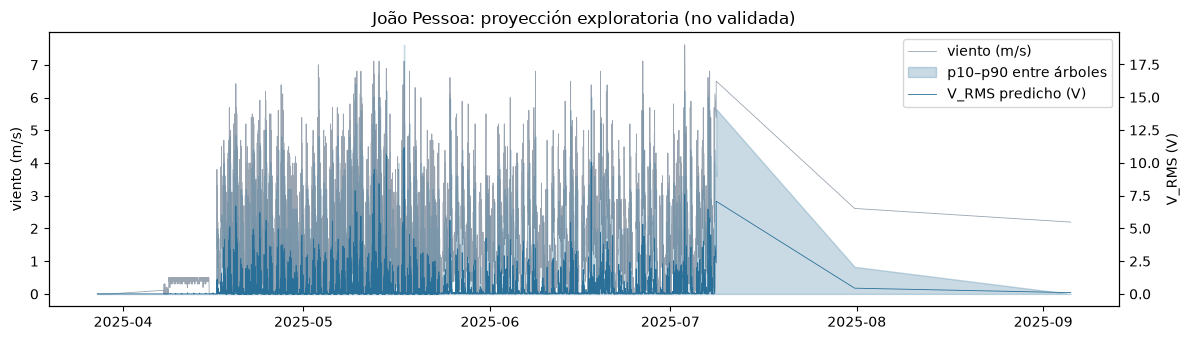

In [17]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(jp.fecha, jp.xmag, color='#9aa5b1', lw=.6, label='viento (m/s)')
ax2 = ax.twinx()
ax2.fill_between(jp.fecha, jp.V_p10, jp.V_p90, color='#2a6f97', alpha=.25, label='p10–p90 entre árboles')
ax2.plot(jp.fecha, jp.V_pred, color='#2a6f97', lw=.6, label='V_RMS predicho (V)')
ax.set_ylabel('viento (m/s)'); ax2.set_ylabel('V_RMS (V)'); ax.set_title('João Pessoa: proyección exploratoria (no validada)')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1+h2, l1+l2, loc='upper right')
plt.tight_layout(); plt.savefig(OUT / 'fig_jpa_proyeccion.png', dpi=200); plt.show()
jp.to_csv(OUT / 'predicciones_jpa.csv', index=False)

## 10. Resumen de lo exportado

| Archivo | Para qué sirve |
|---|---|
| `data/dataset_cajica_limpio.csv` | dataset de entrenamiento ya procesado |
| `models/extra_trees_vrms.joblib` | modelo completo (escalado + Extra Trees) |
| `models/extra_trees_vrms_meta.json` | variables, versiones, métricas, rangos de entrenamiento |
| `outputs/predicciones_jpa.csv` | predicción, banda de incertidumbre, P y E por registro |
| `outputs/fig_*.png` | figuras listas para el paper |

**Recuerda:** las predicciones de João Pessoa son proyecciones exploratorias. Sin mediciones de turbina en ese sitio no hay validación posible;
el diagnóstico fuera de distribución y la banda de incertidumbre son la mejor evidencia disponible.